In [1]:
#the main notebook starts here
from ngsolve import *
import numpy as np
from ngsolve.webgui import Draw
ngsglobals.msg_level = 1
import ipywidgets as widgets
import matplotlib.pyplot as plt
import h5py
#import sksparse.cholmod
#from sksparse.cholmod import cholesky
#from scipy.sparse import csc_matrix
#from scipy.linalg import cholesky

from pathlib import Path
import pandas as pd
from torchvision.datasets.utils import download_url
from tqdm import tqdm

from domain import *
from implicit import implicit
from implicit_update import implicit_update
from download import parse_metadata, download_data, download_darcy
from functions import *

In [2]:

# import darcy file - has to be in directory
try:
    with h5py.File('2D_DarcyFlow_beta100.0_Train.hdf5', 'r') as f:
        #print(list(f.keys()))
        nu = f['/nu'][:]
        tensor = f['/tensor'][:] # tensor with data as nested list of 10000x1x128x128
except:
    print("Check if the name of the file is correct. If the file is already downloaded, check if it is in the correct directory, sometimes the downloading creates a subdirectory")
    download_darcy()

#choose which sample to use - maybe build a loop with multiple samples later
sample = 0
#print(nu[sample])
#print(tensor[sample])

#general parameters
#CHANGE
sigma = 0 #switching parameter (0 e.g. if f is linear wrt q) 
L = 1 #parameter if the functional in the u update is implemented as a simple multiplication

tstart = 0
tend = 1.5
tsteps = int(1e2)

t = Parameter(tstart) #time parameter that will be updated
dt = (tend-tstart)/tsteps

k_u, k_q = 3, 0 # order of feses
maxh = 0.06 # mesh size for domain

# Build domain
dom = domain(maxh = maxh, order_u = k_u, order_q = k_q)
# Build mesh and FE spaces (Ufes for the u update and Qfes for the q update)
mesh, Ufes, Qfes = dom.mesh, dom.Ufes, dom.Qfes

np_random = [np.random.rand(128,128) for _ in range(tsteps+1)]

In [3]:
class grad_bilinear_ufes:
    def __init__(self, q = 0, M = 1):
        if q:
            self.qn = norm(q)
        else:
            self.qn = 0
        self.M = M
        self.fes = Ufes

        # For the case where there is actual q dependence, it would be much better to let this be a parameter and update accordingly
        self.bilinearform = BilinearForm(self.fes)
        self.bilinearform += self.M * Grad(self.fes.TrialFunction()) * Grad(self.fes.TestFunction()) * dx
        self.bilinearform.Assemble()

    def apply(self, f):
        #return -self.M * (f.Diff(x).Diff(x) + f.Diff(y).Diff(y))# doesn work for grid function
        return -self.M * (grad(grad(f)[0])[0]+grad(grad(f)[1])[1])
    def solve(self, f): #Where is this used??? 
        g = GridFunction(Ufes)
        g.vec.data = self.bilinearform.mat.Inverse(freedofs = Ufes.FreeDofs()) * LinearForm(f * self.fes.TestFunction() * dx).Assemble().vec
        return g
    

In [4]:
chosen_sample = tensor[sample][0]
u_exact = GridFunction(Ufes)
#u_exact.Set(to_gridfunc(chosen_sample, Ufes, mesh))
#u_exact.Set(sin(pi*x)*sin(pi*y)*exp(-t))#to_gridfunc(sin(x)*sin(y), Ufes, mesh)#to_gridfunc(chosen_sample, Ufes, mesh)
#u_exact_dt = u_exact.Diff(t) #parameter dependent

if sample == 0: #move the 1-zone to the middle for the 0th sample
    param = list(nu[sample])
    param = param[12:]+param[:12]
else: param = list(nu[sample])
# bring q_exact to 0 at the bnd in the process of setting q_exact
q_exact = to_gridfunc_0(param, Qfes, mesh)
#q_exact.Set(sin(pi*x)*sin(pi*y))
#q_exact = sin(2*pi*x)*sin(pi*y) 
Draw(q_exact,mesh)

#Set up Gridfunctions, that will updated trough the time steps
gfu, gfq, z, z_old = GridFunction(Ufes), GridFunction(Qfes), GridFunction(Ufes), GridFunction(Ufes)


WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

In [5]:
# compute some u_exact from a paramter q and rhs # version with implicit solver - note that the implicit solver is not yet optimized for non hom. Dirichlet BC
dom2 = domain(maxh = 0.06, order_u = 2, order_q = k_q)
mesh2, V = dom2.mesh, dom2.Ufes
u,v = V.TestFunction(),V.TrialFunction()
a = BilinearForm (V, symmetric=True)
a += q_exact * Grad(u) * Grad(v) * dx
a.Assemble()

#Define the linearform (RHS)
#coef_f = CF(1)  #const in time and space
#coef_f = 2*exp(-((x-0.5)*(x-0.5)/.05+(y-0.45)*(y-0.5)/.1))*exp(-t) # gaussian
#exact = sin(pi*x)*sin(pi*y)*cos(pi*t)
coef_f =  to_gridfunc(np_random[0],V, mesh) #random 
coef_0 = GridFunction(coef_f.space)
coef_0.vec.data = coef_f.vec.Copy()
gf = GridFunction (V)
implicit_gen = implicit(bilinearform = a, fes = V, dt = dt)

#gf.Set((2*exp(-((x-0.5)*(x-0.5)/.05+(y-0.45)*(y-0.5)/.1))))
gf.Set(to_gridfunc(np_random[0],V, mesh))
u_exact = [None for i in range (tsteps)]
u_exact_dt = [None for i in range (tsteps)]
counter = 0
while counter<tsteps-dt:
    #coef_f = exact.Diff(t)-(exact.Diff(x)).Diff(x)-(exact.Diff(y)).Diff(y)
    #if t.Get()<.01: Draw(coef_f, mesh2)
    # solve - note that this is not yet optimized for non hom. BC
    implicit_gen.solve_implicit(gf, coef_f, CF(0),gf)
    coef_f =  to_gridfunc(np_random[counter+1],V, mesh) #random 
    auxil = GridFunction(Ufes) 
    auxil.Set (gf)
    u_exact[counter] = GridFunction(Ufes) 
    u_exact[counter].vec.data = auxil.vec.data
    if counter>0: u_exact_dt[counter] = (u_exact[counter]-u_exact[counter-1])/dt #has to be computed as a differential quotient
    else: u_exact_dt[counter] = (u_exact[counter])/dt #insert u_exact if nessasary
    counter += 1

Draw(u_exact[0])
Draw(u_exact[99])

#print(norm(exact-u_exact[179])/norm(u_exact[179]))

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

BaseWebGuiScene

In [6]:
print(type(z_old))
# setup implicit solvers
grads = grad_bilinear_ufes()
implicit_u = implicit(bilinearform = grads.bilinearform, fes = Ufes, dt = dt) #linearform is now passed below as it is time dependent# If C were to depend on norm q, then this would need to be in the loop and updated each time - the implicit solver code isn't optimized for this yet!
implicit_q = implicit(bilinearform = None, fes = Qfes, dt = dt)  #change bilinearform to            

<class 'ngsolve.comp.GridFunction'>


WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

<class 'ngsolve.comp.GridFunction'>
<class 'ngsolve.comp.GridFunction'>
<class 'ngsolve.comp.GridFunction'>
1.4849999999999977//noiselevel: 0.0


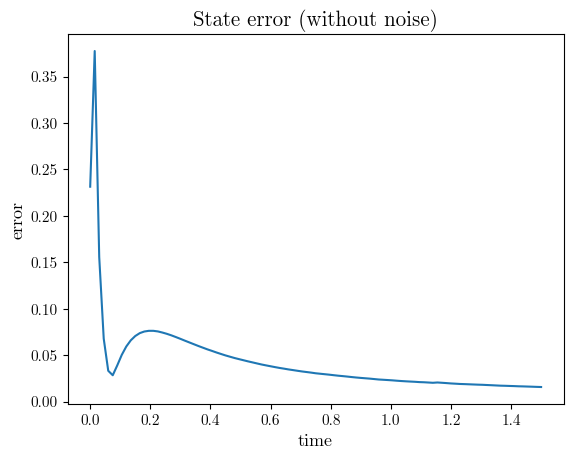

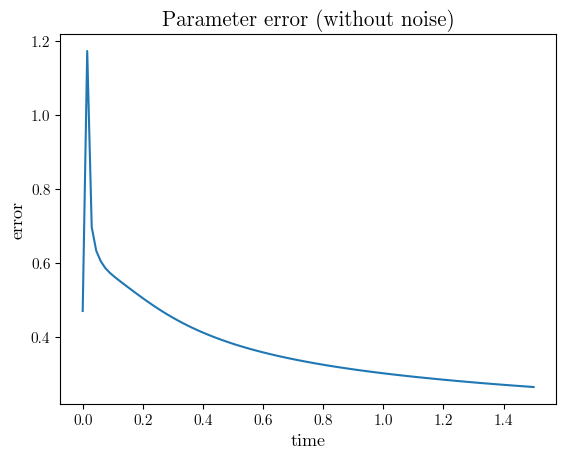

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

<class 'ngsolve.comp.GridFunction'>
<class 'ngsolve.comp.GridFunction'>
<class 'ngsolve.comp.GridFunction'>
1.4849999999999977/noiselevel: 0.03


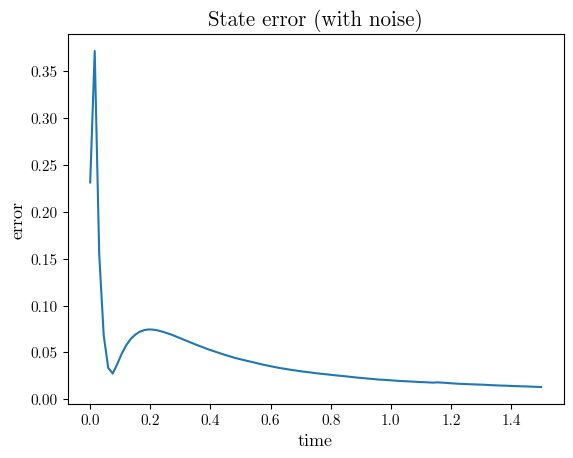

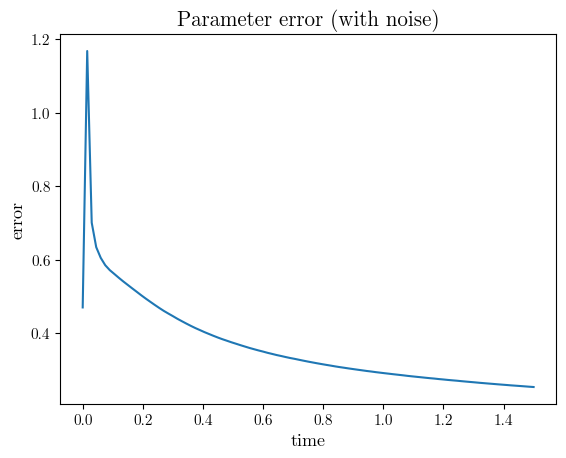

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

In [7]:
# MRAS
z, z_old = GridFunction(Ufes),GridFunction(Ufes)
for noise_level in [0.0,0.03]:  #different noise levels
    saved_gfu = []
    saved_gfq = []
    # Initial u and q
    gfu.Set(coef_0)
    r = (x-.5)**2 + (y-.5)**2
    radius = .42
    gfq.Set(IfPos(radius**2 - r,1,0))
    #initial error computation
    error_u = [norm(gfu-u_exact[0],mesh)]
    error_q = [norm(gfq-q_exact,mesh)]
    t.Set(0)
    z_old.Set(CF(0))
    while t < tend-dt:
        print("\r",t.Get(),"/",sep="",end="")
        # Get updated data z and g and compute time derivative zt
        z =  add_noise(u_exact[int(t.Get()/dt)],noise_level,Ufes,mesh)
        zt = GridFunction(Ufes)
        zt.vec.data = z.vec.Copy()
        zt.vec.data -= z_old.vec.Copy()#u_exact_dt[int(t.Get()/dt)]#
        zt.vec.data /= dt
        z_old.vec.data = z.vec.Copy()
        #g = u_exact_dt[int(t.Get()/dt)] + f(q_exact, u_exact[int(t.Get()/dt)])
        g = GridFunction(coef_f.space)
        g.vec.data = coef_f.vec.Copy() # gaussian

        # Implicit solve for q
        f_deriv = Grad(z)[0] * (Grad(gfu)[0] - Grad(z)[0]) + Grad(z)[1] * (Grad(gfu)[1] - Grad(z)[1]) # + (z**3 * (3/2) * norm(q)**(-1/3) * q + z**3*norm(q)**(2/3))*(gfu-z) #add nonlinear part, check derivation
        rhs_q = f_deriv  -sigma*(zt-g) #nonlinear part, the sigma*f(q,z) part should remain implicit and still has to be coded
        implicit_q.solve_implicit(gfq, f_deriv, CF(0),z) # Updates gfq behind the scenes
        error_q.append(norm(gfq-q_exact,mesh))
        t += dt    # Update time
        saved_gfq.append(gfq.vec.FV().NumPy().copy())

        # Implicit solve for u
        rhs_u = GridFunction(g.space)
        rhs_u.vec.data = g.vec.Copy() #COPY
        implicit_u.solve_implicit(gfu, rhs_u, 1-gfq,z) # Updates gfu behind the scenes
        error_u.append(norm(gfu-u_exact[int(t.Get()/dt)],mesh))
        saved_gfu.append(gfu.vec.FV().NumPy().copy())

    print("noiselevel: "+str(noise_level))
    plot_error(tstart,tend,tsteps,noise_level,error_u,error_q)
    draw_gridfuncs (tsteps,u_exact,q_exact,gfu,gfq,mesh)
    save (mesh,noise_level,saved_gfu,saved_gfq)
    

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

BaseWebGuiScene

In [9]:
Draw(u_exact[tsteps-1]-gfu,mesh, settings={"Objects": {"Wireframe": False}})
Draw(q_exact-gfq,mesh, settings={"Objects": {"Wireframe": False}})

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

BaseWebGuiScene